# Quantum Fidelity Kernel Decoding for Surface Codes

## 1. Purpose and Motivations

The purpose of this project is to show how Q-SVM can be used as a decoder to predict logical errors from measured syndromes in surface codes. Why is it interesting for me? My engineering team and I are creating surface codes in Qiskit, specifically for distance $3$, $5$, $7$, using the MWPM (Minimum Weight Perfect Matching) decoder in PyMatching. I wanted to try something else to get a better understanding of this topic, and Q-SVM seems really interesting for that.

## 2. Abstract

Quantum Error Correction Codes are used in quantum computers to detect and correct errors which occur in qubits. The reasons for those errors are various and we simply call noise. There are 2 kinds of errors in qubits:

- bit-flip - $(X)$ - flips the computational basis states, turning $\ket{0}$ into $\ket{1}$ and $\ket{1}$ into $\ket{0}$

- phase-flip - $(Z)$ - flips the sign of the $\ket{1}$ state, turning $\ket{1}$ into $-\ket{1}$ while leaving $\ket{0}$ unchanged

There is also a third one $(Y)$ which is bit-flip and phase-flip happening together, but we can detect and correct them separately. Firstly we will be using rotated surface code for distance $d=3$. It will be encoding $1$ logical qubit and we need for that $17$ qubits - $8$ ancillas and $9$ data qubits. Later, we will also scale the experiment to distance $d=5$. I will focus on logical bit-flip errors in the $Z$ memory experiment, because in surface codes the idea of correcting bit and phase flips is the same. The last question remains - why Q-SVM? Syndrome data is binary (0s and 1s), but the mapping between triggered detectors and logical errors is not linear, so I want to test whether a quantum kernel separates these patterns in a higher-dimensional Hilbert space or not.

## 3. Project Environment and setup

Libraries and their versions are provided in the `requirements.txt` file. To install and run we need to open the terminal and run these commands:

```bash
uv venv --python 3.12
.venv\Scripts\activate
uv pip install -r requirements.txt
```

Let's import them.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stim
import pymatching

from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC


print(f"numpy version: {np.__version__}")
print(f"pandas version: {pd.__version__}")
print(f"matplotlib version: {plt.matplotlib.__version__}")
print(f"stim version: {stim.__version__}")
print(f"pymatching version: {pymatching.__version__}")

numpy version: 2.5.5
pandas version: 3.1.1
matplotlib version: 3.11.2
stim version: 1.16.0
pymatching version: 2.4.0


## 4. Dataset Generation and Refinement

Firstly we need a circuit and data from it. We want to generate circuit from which we will collect:

- Syndrome - the measurement outcomes of stabilizers that check the parity of neighbouring data qubits to detect errors without collapsing quantum state
- Observables - The true target label indicating whether a logical bit-flip error occurred or the logical state survived intact. It is possible because we are preparing in simulator qubits as $\ket{0}$ states.

That will be our data, which we must refine.

In [3]:
physical_error_rate = 0.05 # Safe value for testing, but not really realistic.

"Let's start with small surface code."
circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    distance=3, 
    rounds=1,
    before_round_data_depolarization=physical_error_rate,
)

sampler = circuit.compile_detector_sampler(seed=1234)
shots = 1000
syndromes, observables = sampler.sample(shots=shots, separate_observables=True)

X_raw = syndromes.astype(int)
y = observables.ravel().astype(int)

print("X shape:", X_raw.shape)
print("y shape:", y.shape)
print("Logical error rate (raw):", np.mean(y))

"We must check for any columns in X that are all zeros, as these will not be useful for training a model. We can remove these columns to refine our dataset."

active_cols = X_raw.sum(axis=0) > 0
X = X_raw[:, active_cols]

"We see that y is a 1D array, which is suitable for training a model. We don't need to refine it."

print("X shape:", X.shape)

X shape: (1000, 8)
y shape: (1000,)
Logical error rate (raw): 0.103
X shape: (1000, 4)


## 5. Q-SVM Model Training and Evaluation

In this section we want to train a model from our refined data to detect and correct errors. We will divide datasets into training and test sets using a standard 80/20 split, encode the syndromes into a 4-qubit quantum state and compute the fidelity kernel matrix to fit our Q-SVM classifier.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

feature_map = zz_feature_map(feature_dimension=X_train.shape[1], reps=2, entanglement='linear') # We use linear entanglement for simplicity. It is easier to visualize and understand, but other entanglement strategies can be used as well.

def compute_fidelity_kernel(A, B):
    """Compute the fidelity kernel between two sets of data points."""
    
    states_A = [Statevector.from_instruction(feature_map.assign_parameters(x * np.pi/2)).data for x in A] # We scale the input data by pi/2 to ensure that the feature map is well-defined and does not produce trivial states. This scaling is important for the fidelity kernel to capture meaningful information about the data points.
    states_B = [Statevector.from_instruction(feature_map.assign_parameters(x * np.pi/2)).data for x in B]
    overlaps = np.abs(np.matmul(states_A, np.conj(states_B).T)) ** 2 # inner product
    return overlaps

K_train = compute_fidelity_kernel(X_train, X_train)
K_test = compute_fidelity_kernel(X_test, X_train)

qsvm = SVC(kernel='precomputed')
qsvm.fit(K_train, y_train)

y_pred = qsvm.predict(K_test)
ler_qsvm = np.mean(y_pred != y_test)

print("Logical error rate:", ler_qsvm)

Logical error rate: 0.015


What does ``compute_fidelity_kernel`` function do? Each syndrome is just a sequence of 0s and 1s. We use our feature map circuit to encode each syndrome into a quantum state:

$$\ket{\phi(x)} = U_{\Phi}(x \cdot \frac{\pi}{2}) \ket{0}^{\otimes n}$$

We multiply by $\frac{\pi}{2}$ because we want 0s and 1s be on a different sides of Bloch sphere! 

Then we compute the kernel between syndromes, which is just the quantum fidelity (overlap) between their states: 

$$K(x, x') = |\braket{\phi(x) | \phi(x')}|^2$$

If two syndromes are the same, the overlap is 1. If they are completely different, it drops to 0.

We see the result, but what does it mean? Let's compare it with other methods.

## 6. Comparison

We will compare our Q-SVM result with different methods to see how well it actually performs.

### 6.1 raw LER

No correction used. It means that there is direct measurement baseline without active decoding, simply looking at whether data qubits suffered a logical flip. It's not really a method, but lack of that, so that means properly working decoder should beat this number (or to be equal if there is no errors)

### 6.2 SVM 

classical counterpart of our method using RBF kernel. It treats our measured syndromes purely as flat feature vectors of 0s and 1s. It tries to learn the classification boundary from data without having any clue, about the physical grid or topology of the surface code.

### 6.3 MWPM  

Minimum Weight Perfect Matching, it is a standard classical graph algorithm used in surface codes. Physical errors on data qubits form chains, but our stabilizers can only detect their endpoints. MWPM solves this by converting this decoding problem into a graph where detectors are vertices and possible errors are edges with weights $w = \ln{((1-p)/p)}$ based on their probability. When errors occur and trigger non-zero syndromes, the algorithm pairs these defect endpoints together so that the total weight of the connections is minimized, and then applies the correction along those most probable paths. Unlike SVM, it uses full knowledge of the circuit and error graph from Stim.

In [12]:
"Raw LER"
ler_raw = np.mean(y_test)

"Classical SVM"
classical_svm = SVC(kernel="rbf", random_state=42)
classical_svm.fit(X_train, y_train)
ler_classical_svm = np.mean(classical_svm.predict(X_test) != y_test)

"MWPM"
_, X_test_raw, _, _ = train_test_split(X_raw, y, test_size=0.2, random_state=42)
dem = circuit.detector_error_model(decompose_errors=True)
matcher = pymatching.Matching.from_detector_error_model(dem)
y_pred_mwpm = matcher.decode_batch(X_test_raw).ravel()
ler_mwpm = np.mean(y_pred_mwpm != y_test)

print(f"Raw LER:           {ler_raw:.4f}")
print(f"Classical SVM LER: {ler_classical_svm:.4f}")
print(f"Q-SVM LER:         {ler_qsvm:.4f}")
print(f"MWPM LER:          {ler_mwpm:.4f}")

Raw LER:           0.1100
Classical SVM LER: 0.0150
Q-SVM LER:         0.0150
MWPM LER:          0.0150


We see that on small distance and number of rounds our methods did the same. But we don't believe they are the same, do we? Let's stress them more! First let's write functions to simplify testing and make sure that computation is efficient. We will also collect information about time.

In [13]:
def generate_surface_code_data(distance, rounds, physical_error_rate, shots, seed=1234):
    """Generate surface code data for a given distance, number of rounds, physical error rate, and number of shots."""

    circuit = stim.Circuit.generated(
        "surface_code:rotated_memory_z",
        distance=distance,
        rounds=rounds,
        before_round_data_depolarization=physical_error_rate,
        before_measure_flip_probability=physical_error_rate if rounds > 1 else 0.0,
    )
    sampler = circuit.compile_detector_sampler(seed=seed)
    syndromes, observables = sampler.sample(shots=shots, separate_observables=True)

    X_raw = syndromes.astype(int)
    y = observables.ravel().astype(int)

    active_cols = X_raw.sum(axis=0) > 0
    X = X_raw[:, active_cols]

    return circuit, X_raw, X, y

def compute_fidelity_kernel(A, B, feature_map):
    """Compute the quantum fidelity kernel matrix between datasets A and B."""

    unique_A, inverse_A = np.unique(A, axis=0, return_inverse=True)
    unique_B, inverse_B = np.unique(B, axis=0, return_inverse=True)

    states_A = []
    for x in unique_A:
        bound_circuit = feature_map.assign_parameters(x * (np.pi / 2))
        states_A.append(Statevector.from_instruction(bound_circuit).data)

    states_B = []
    for x in unique_B:
        bound_circuit = feature_map.assign_parameters(x * (np.pi / 2))
        states_B.append(Statevector.from_instruction(bound_circuit).data)

    kernel_unique = np.abs(np.matmul(states_A, np.conj(states_B).T)) ** 2

    return kernel_unique[inverse_A][:, inverse_B]


def evaluate_decoders(distance, rounds, physical_error_rate, shots, reps=2, seed=1234):
    """Evaluate Raw, Classical SVM, Q-SVM, and MWPM decoders on a given surface code setup."""
    circuit, X_raw, X, y = generate_surface_code_data(
        distance=distance,
        rounds=rounds,
        physical_error_rate=physical_error_rate,
        shots=shots,
        seed=seed,
    )

    X_train, X_test, y_train, y_test, _, X_test_raw = train_test_split(
        X, y, X_raw, test_size=0.2, stratify=y, random_state=42
    )

    ler_raw = np.mean(y_test)

    t0 = time.perf_counter()
    csvm = SVC(kernel="rbf", random_state=42)
    csvm.fit(X_train, y_train)
    ler_csvm = np.mean(csvm.predict(X_test) != y_test)
    time_csvm = time.perf_counter() - t0

    t0 = time.perf_counter()
    feature_map = zz_feature_map(feature_dimension=X_train.shape[1], reps=reps, entanglement="linear")
    K_train = compute_fidelity_kernel(X_train, X_train, feature_map)
    K_test = compute_fidelity_kernel(X_test, X_train, feature_map)
    qsvm = SVC(kernel="precomputed")
    qsvm.fit(K_train, y_train)
    ler_qsvm = np.mean(qsvm.predict(K_test) != y_test)
    time_qsvm = time.perf_counter() - t0

    t0 = time.perf_counter()
    dem = circuit.detector_error_model(decompose_errors=True)
    matcher = pymatching.Matching.from_detector_error_model(dem)
    y_pred_mwpm = matcher.decode_batch(X_test_raw).ravel()
    ler_mwpm = np.mean(y_pred_mwpm != y_test)
    time_mwpm = time.perf_counter() - t0

    return {
        "raw": ler_raw,
        "csvm": ler_csvm,
        "qsvm": ler_qsvm,
        "mwpm": ler_mwpm,
        "time_csvm": time_csvm,
        "time_qsvm": time_qsvm,
        "time_mwpm": time_mwpm,
    }

## 7. Testing different variables

We will run several tests across different parameter values to get a different results. In next chapter we will analyze them.

In [14]:
results_all = []

for d in [3, 5]:
    for p in [0.01, 0.03, 0.05, 0.08, 0.12]:
        res = evaluate_decoders(distance=d, rounds=1, physical_error_rate=p, shots=3000)
        res["p"] = p
        res["distance"] = d
        res["rounds"] = 1
        res["shots"] = 3000
        results_all.append(res)

for d in [3, 5]:
    for s in [1000, 2000, 3000]:
        res = evaluate_decoders(distance=d, rounds=1, physical_error_rate=0.05, shots=s)
        res["p"] = 0.05
        res["distance"] = d
        res["rounds"] = 1
        res["shots"] = s
        results_all.append(res)

for r in [1, 2]:
    res = evaluate_decoders(distance=3, rounds=r, physical_error_rate=0.05, shots=1000)
    res["p"] = 0.05
    res["distance"] = 3
    res["rounds"] = r
    res["shots"] = 1000
    results_all.append(res)

## 8. Results Analysis and Visualization

We have our results! Let's perform some analysis and visualisations to see how our methods performed and how Q-SVM compared to the other decoders. For that we will use pandas and matplotlib libraries.

In [15]:
df = pd.DataFrame(results_all)

"Mean LER for each method"
raw_mean = df["raw"].mean()
csvm_mean = df["csvm"].mean()
qsvm_mean = df["qsvm"].mean()
mwpm_mean = df["mwpm"].mean()

print("Average LER")
print("Raw:                ", round(raw_mean, 4))
print("Classical SVM:      ", round(csvm_mean, 4))
print("Q-SVM:              ", round(qsvm_mean, 4))
print("MWPM:               ", round(mwpm_mean, 4))

"Standard deviation of LER"
raw_std = df["raw"].std()
csvm_std = df["csvm"].std()
qsvm_std = df["qsvm"].std()
mwpm_std = df["mwpm"].std()

print("\nStandard Deviation")
print("Raw std:            ", round(raw_std, 4))
print("Classical SVM std:  ", round(csvm_std, 4))
print("Q-SVM std:          ", round(qsvm_std, 4))
print("MWPM std:           ", round(mwpm_std, 4))

"Differences: SVM - Q-SVM (positive means Q-SVM is better)"
diff_svm = df["csvm"] - df["qsvm"]
diff_mwpm = df["mwpm"] - df["qsvm"]

print("\nAverage Differences")
print("Classical SVM - Q-SVM:", round(diff_svm.mean(), 4))
print("MWPM - Q-SVM:         ", round(diff_mwpm.mean(), 4))

"Head-to-head comparison: Wins, Ties, and Losses for Q-SVM"
wins_svm = np.sum(diff_svm > 0)
ties_svm = np.sum(diff_svm == 0)
losses_svm = np.sum(diff_svm < 0)

wins_mwpm = np.sum(diff_mwpm > 0)
ties_mwpm = np.sum(diff_mwpm == 0)
losses_mwpm = np.sum(diff_mwpm < 0)

print("\nQ-SVM vs Classical SVM")
print(f"Wins: {wins_svm} | Ties: {ties_svm} | Losses: {losses_svm}")

print("\nQ-SVM vs MWPM")
print(f"Wins: {wins_mwpm} | Ties: {ties_mwpm} | Losses: {losses_mwpm}")

"Mean Squared Error (how close Q-SVM is to SVM and MWPM)"
mse_svm = np.mean(diff_svm ** 2)
mse_mwpm = np.mean(diff_mwpm ** 2)

print("\nMean Squared Error (MSE)")
print("MSE(Q-SVM vs Classical SVM):", round(mse_svm, 6))
print("MSE(Q-SVM vs MWPM):         ", round(mse_mwpm, 6))

print(f"Mean time of Q-SVM: {df['time_qsvm'].mean():.4f} s")
print(f"Mean time of Classical SVM: {df['time_csvm'].mean():.4f} s")
print(f"Mean time of MWPM:  {df['time_mwpm'].mean():.4f} s")

speedup_mwpm = df['time_qsvm'].mean() / df['time_mwpm'].mean()
speedup_csvm = df['time_qsvm'].mean() / df['time_csvm'].mean()
print(f"\nSpeedup: MWPM is {speedup_mwpm:.1f}x faster than Q-SVM")
print(f"Speedup: Classical SVM is {speedup_csvm:.1f}x faster than Q-SVM")

Average LER
Raw:                 0.1309
Classical SVM:       0.0453
Q-SVM:               0.0366
MWPM:                0.022

Standard Deviation
Raw std:             0.0729
Classical SVM std:   0.0515
Q-SVM std:           0.0438
MWPM std:            0.0269

Average Differences
Classical SVM - Q-SVM: 0.0087
MWPM - Q-SVM:          -0.0145

Q-SVM vs Classical SVM
Wins: 8 | Ties: 10 | Losses: 0

Q-SVM vs MWPM
Wins: 0 | Ties: 9 | Losses: 9

Mean Squared Error (MSE)
MSE(Q-SVM vs Classical SVM): 0.00024
MSE(Q-SVM vs MWPM):          0.000685
Mean time of Q-SVM: 22.6880 s
Mean time of Classical SVM: 0.0289 s
Mean time of MWPM:  0.0008 s

Speedup: MWPM is 28887.8x faster than Q-SVM
Speedup: Classical SVM is 784.2x faster than Q-SVM


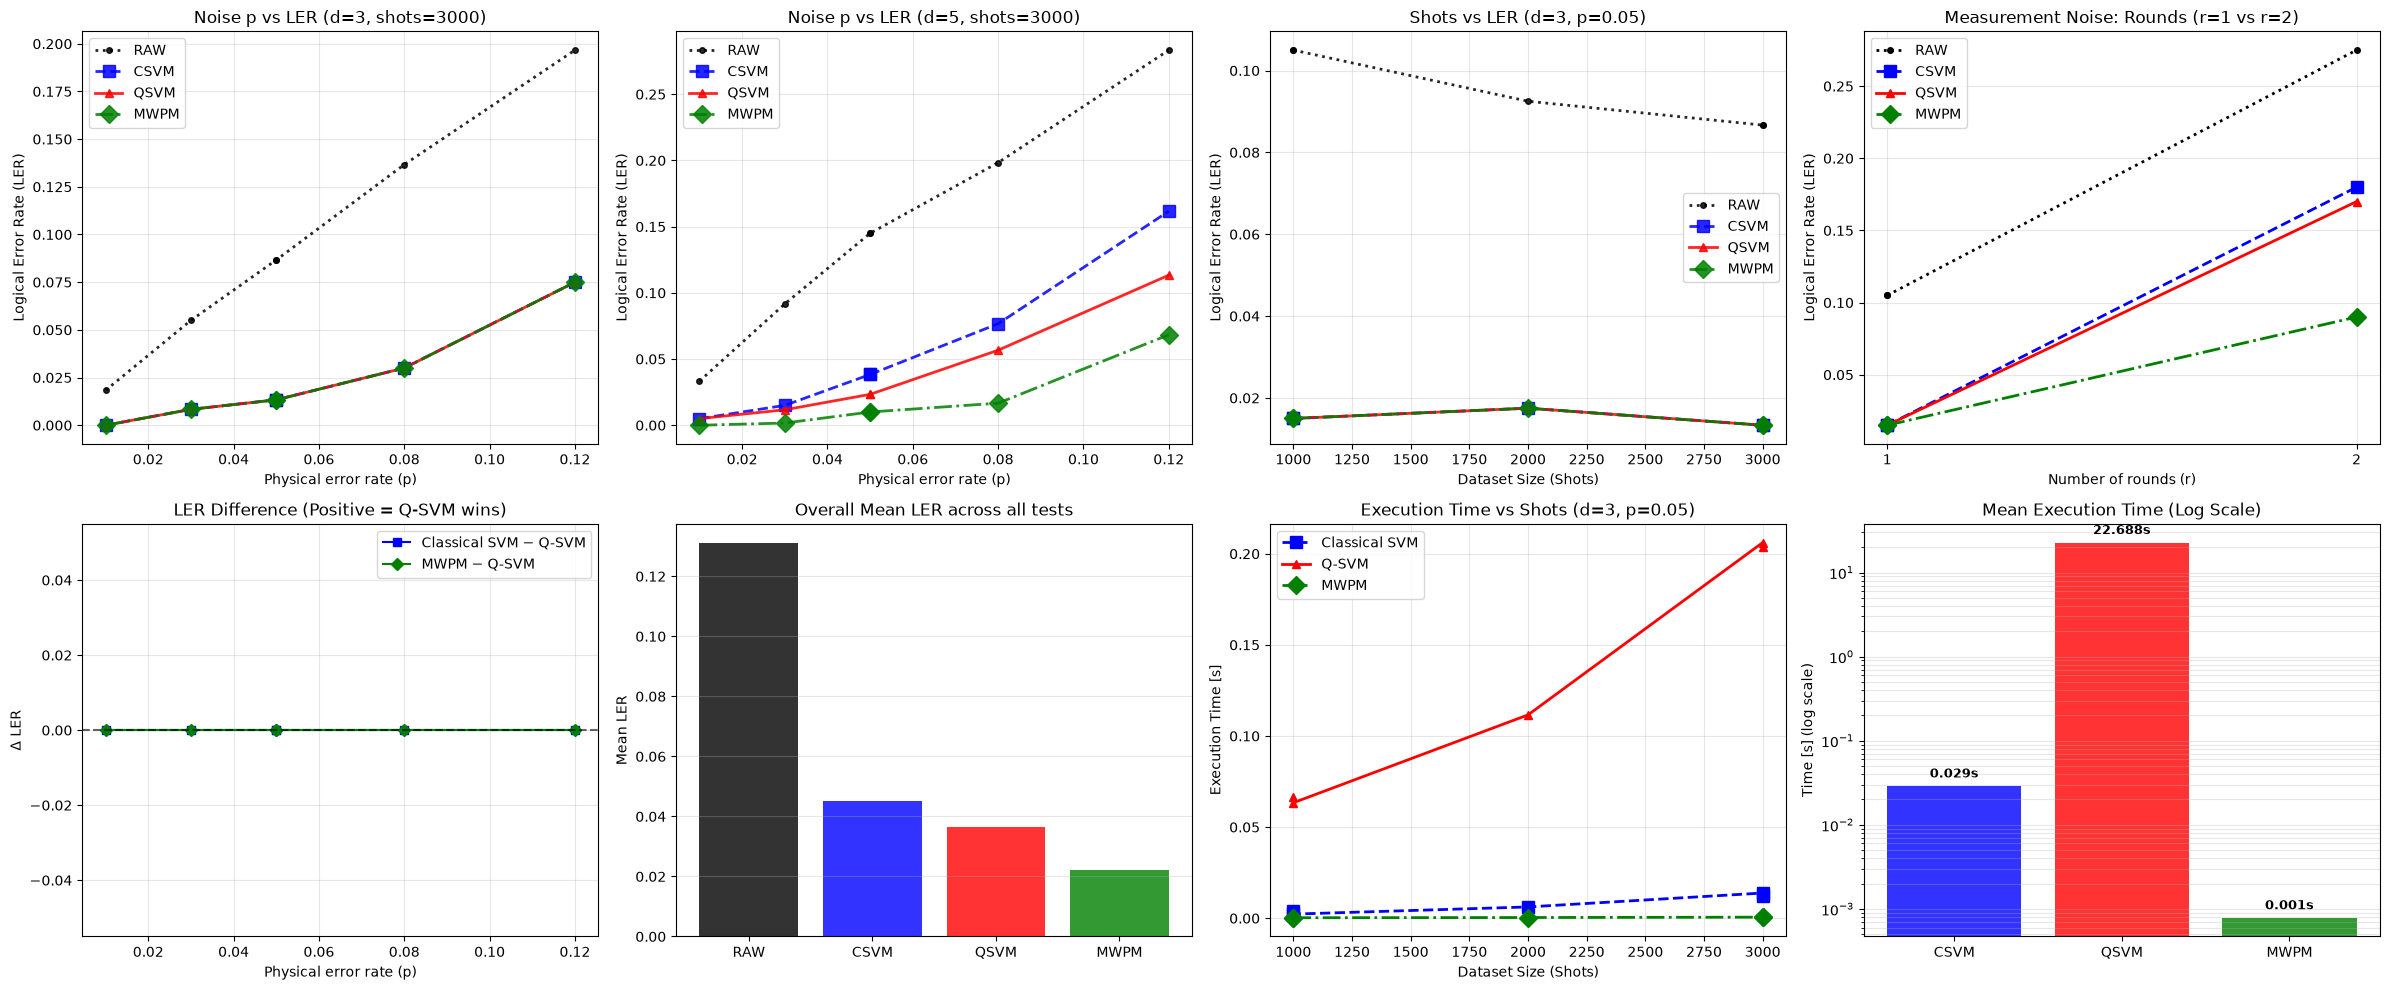

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(24, 10))

colors = {"raw": "black", "csvm": "blue", "qsvm": "red", "mwpm": "green"}
styles = {"raw": ":", "csvm": "--", "qsvm": "-", "mwpm": "-."}
markers = {"raw": "o", "csvm": "s", "qsvm": "^", "mwpm": "D"}
marker_sizes = {"raw": 4, "csvm": 8, "qsvm": 6, "mwpm": 9}
methods = ["raw", "csvm", "qsvm", "mwpm"]

noise_d3 = df[(df["rounds"] == 1) & (df["shots"] == 3000) & (df["distance"] == 3)].sort_values("p")
noise_d5 = df[(df["rounds"] == 1) & (df["shots"] == 3000) & (df["distance"] == 5)].sort_values("p")
shots_d3 = df[(df["rounds"] == 1) & (df["p"] == 0.05) & (df["distance"] == 3)].sort_values("shots")
rounds_data = df[(df["distance"] == 3) & (df["p"] == 0.05) & (df["shots"] == 1000)].sort_values("rounds")

for m in methods:
    axes[0, 0].plot(noise_d3["p"], noise_d3[m], linestyle=styles[m], marker=markers[m],
                    markersize=marker_sizes[m], label=m.upper(), color=colors[m], alpha=0.85, linewidth=2)
axes[0, 0].set_title("Noise p vs LER (d=3, shots=3000)")
axes[0, 0].set_xlabel("Physical error rate (p)")
axes[0, 0].set_ylabel("Logical Error Rate (LER)")
axes[0, 0].grid(alpha=0.3)
axes[0, 0].legend()

for m in methods:
    axes[0, 1].plot(noise_d5["p"], noise_d5[m], linestyle=styles[m], marker=markers[m],
                    markersize=marker_sizes[m], label=m.upper(), color=colors[m], alpha=0.85, linewidth=2)
axes[0, 1].set_title("Noise p vs LER (d=5, shots=3000)")
axes[0, 1].set_xlabel("Physical error rate (p)")
axes[0, 1].set_ylabel("Logical Error Rate (LER)")
axes[0, 1].grid(alpha=0.3)
axes[0, 1].legend()

for m in methods:
    axes[0, 2].plot(shots_d3["shots"], shots_d3[m], linestyle=styles[m], marker=markers[m],
                    markersize=marker_sizes[m], label=m.upper(), color=colors[m], alpha=0.85, linewidth=2)
axes[0, 2].set_title("Shots vs LER (d=3, p=0.05)")
axes[0, 2].set_xlabel("Dataset Size (Shots)")
axes[0, 2].set_ylabel("Logical Error Rate (LER)")
axes[0, 2].grid(alpha=0.3)
axes[0, 2].legend()

for m in methods:
    axes[0, 3].plot(rounds_data["rounds"], rounds_data[m], linestyle=styles[m], marker=markers[m],
                    markersize=marker_sizes[m], label=m.upper(), color=colors[m], linewidth=2)
axes[0, 3].set_xticks([1, 2])
axes[0, 3].set_title("Measurement Noise: Rounds (r=1 vs r=2)")
axes[0, 3].set_xlabel("Number of rounds (r)")
axes[0, 3].set_ylabel("Logical Error Rate (LER)")
axes[0, 3].grid(alpha=0.3)
axes[0, 3].legend()

diff_d3_svm = noise_d3["csvm"] - noise_d3["qsvm"]
diff_d3_mwpm = noise_d3["mwpm"] - noise_d3["qsvm"]
axes[1, 0].plot(noise_d3["p"], diff_d3_svm, marker="s", label="Classical SVM − Q-SVM", color="blue", linewidth=1.5)
axes[1, 0].plot(noise_d3["p"], diff_d3_mwpm, marker="D", label="MWPM − Q-SVM", color="green", linewidth=1.5)
axes[1, 0].axhline(0, color="black", linestyle="--", alpha=0.6)
axes[1, 0].set_title("LER Difference (Positive = Q-SVM wins)")
axes[1, 0].set_xlabel("Physical error rate (p)")
axes[1, 0].set_ylabel("Δ LER")
axes[1, 0].grid(alpha=0.3)
axes[1, 0].legend()

means_ler = [raw_mean, csvm_mean, qsvm_mean, mwpm_mean]
axes[1, 1].bar(["RAW", "CSVM", "QSVM", "MWPM"], means_ler, color=["black", "blue", "red", "green"], alpha=0.8)
axes[1, 1].set_title("Overall Mean LER across all tests")
axes[1, 1].set_ylabel("Mean LER")
axes[1, 1].grid(axis="y", alpha=0.3)

timing_methods = ["csvm", "qsvm", "mwpm"]
timing_labels = {"csvm": "Classical SVM", "qsvm": "Q-SVM", "mwpm": "MWPM"}
for m in timing_methods:
    axes[1, 2].plot(shots_d3["shots"], shots_d3[f"time_{m}"],
                    linestyle=styles[m], marker=markers[m], markersize=marker_sizes[m],
                    label=timing_labels[m], color=colors[m], linewidth=2)
axes[1, 2].set_title("Execution Time vs Shots (d=3, p=0.05)")
axes[1, 2].set_xlabel("Dataset Size (Shots)")
axes[1, 2].set_ylabel("Execution Time [s]")
axes[1, 2].grid(alpha=0.3)
axes[1, 2].legend()

mean_times = [df["time_csvm"].mean(), df["time_qsvm"].mean(), df["time_mwpm"].mean()]
bars = axes[1, 3].bar(["CSVM", "QSVM", "MWPM"], mean_times, color=["blue", "red", "green"], alpha=0.8)
axes[1, 3].set_yscale("log")
axes[1, 3].set_title("Mean Execution Time (Log Scale)")
axes[1, 3].set_ylabel("Time [s] (log scale)")
axes[1, 3].grid(axis="y", which="both", alpha=0.3)

for bar, t_val in zip(bars, mean_times):
    y_pos = bar.get_height()
    axes[1, 3].annotate(f"{t_val:.3f}s",
                        xy=(bar.get_x() + bar.get_width() / 2, y_pos),
                        xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

## 9. Conclusions

What can we see? MWPM is a clear winner, there is no doubt about it. Still, Q-SVM gets strong results and even beats classical SVM on $d=5$ in our tests. However, let's be honest: Q-SVM is much, much slower than the classical decoders. Why is that? Because on a classical computer, simulating quantum states requires tracking the full statevector, which lives in a $2^n$-dimensional Hilbert space. While MWPM runs really fast in C++ and classical SVM computes kernel distances in polynomial time, our simulator pays an exponential price. 

## 10. Summary

We saw how Q-SVM compared to other classical methods works as a decoder in surface codes, which are a family of error correction codes for quantum computers. We explained what syndromes and observables are, and why we want to detect errors without collapsing the quantum state.

We tested 3 decoders to correct those errors:

Classical SVM (machine learning baseline)
Q-SVM (quantum fidelity kernel)
MWPM (classical graph algorithm)

We visualized how they performed across different noise rates $(p)$, dataset sizes (shots), and code distance $(d=3$ and $d=5)$, and we also compared their execution times.

What did we find? MWPM is a clear winner in both accuracy and speed. However, Q-SVM takes a solid second place and beats classical SVM, proving that quantum kernels can learn error patterns without any built-in knowledge of the code geometry. The only real issue is the simulation time on classical hardware.

#### Author: Sebastian Półtorak

#### Bibliography

[1] Bartkiewicz K., "Quantum Machine Learning - Lecture 9: Inference: Linear Models and Repeat-Until-Succes, Quantum Kernels, Representer Theorem, Gram Matrices. Teaching materials (.pdf file), academic year 2026/2027.

[2] Pesah A. An iteractive introduction to the surface code. Blog post (https://arthurpesah.me/blog/2023-05-13-surface-code/), May 13, 2023.

[3] Higgott O. PyMatching: A Python package for decoding quantum codes with minimum-weight perfect matching. Preprint (arXiv:2105.13082v2), July 2021.

[4] Wikipedia Contributors (2026). 'Support Vector Machine'. Wikipedia, The Free Encyclopedia. Access: https://en.wikipedia.org/wiki/Support_vector_machine

[5] Veloso de Souza T. (2022). 'Quantum Support Vector Machine (QSVM)'. Medium (MIT 6.s089 — Intro to Quantum Computing). Acces: https://medium.com/mit-6-s089-intro-to-quantum-computing/quantum-support-vector-machine-qsvm-134eff6c9d3b